# 线性回归课堂笔记：从相关分析到模型评估

本 Notebook 按《机器学习课堂笔记(4)》新增内容整理，覆盖：

- conda 环境与 Jupyter 内核
- 广告投放案例：相关系数、散点图
- 假设函数、sklearn 要求的数据形状
- 单特征 / 多特征线性回归
- 预测、MAE / RMSE / R² 与残差图

数据：`data/广告数据.csv`（200 周，微信/微博/抖音投入与销售额）。

依赖：

```bash
pip install numpy pandas scikit-learn matplotlib
```

> 本 Notebook 位于 `notebooks/` 目录，数据路径统一写作 `../data/广告数据.csv`；如果在项目根目录运行，请改成 `data/广告数据.csv`。

## 0. conda 环境与 Jupyter 内核

每个 conda 环境是一套独立隔离的 Python + 包版本，环境之间互不干扰。`base` 是 Anaconda 默认环境，项目依赖建议单独建环境。

### 0.1 常用命令

```bash
# 查看所有环境（同时能看到安装位置）
conda env list

# 创建环境
conda create -n 环境名称

# 创建时直接装好 Python 和 Jupyter 内核
conda create -n 环境名称 python=3.12 ipykernel -y

# 激活 / 退出
conda activate 环境名称
conda deactivate

# 删除环境（先退出要删除的环境）
conda env remove -n 环境名称
```

### 0.2 把环境注册到 Jupyter

Jupyter 默认不知道你新建的 conda 环境，需要注册内核：

```bash
conda activate 环境名称
python -m ipykernel install --user --name 项目名 --display-name "Jupyter 中显示的名称"
```

- `--name`：内核的唯一标识，建议用英文；
- `--display-name`：Jupyter 下拉框中显示的名字，可以用中文；
- 注册后刷新或重启 Jupyter，才能看到新内核。

查看和删除内核：

```bash
jupyter kernelspec list
jupyter kernelspec remove 内核名称
```

注意：`jupyter kernelspec remove` 用的是**内核名称**（`--name` 的值），不是 conda 环境名称。

> Python 版本建议 3.11 / 3.12。笔记里写的 Python 3.14 很新，部分科学计算包可能尚未完全适配。

## 1. 从分类到回归

- **分类**：输出类别，例如“这朵花是哪个品种”。
- **回归**：输出连续数值，例如“这周销售额是多少万元”。

线性回归就是找一条最贴合数据的直线（或多个特征时的超平面），描述特征与标签之间的近似线性关系，再用它做预测。

### 广告案例的 T、P、E

一家网店记录了 200 周的数据：每周在微信、微博、抖音三个渠道各投多少钱（千元），这一周卖了多少钱（万元）。

- **T（任务）**：根据三个渠道的投入预测销售额；
- **P（性能）**：预测值与真实值平均差多少万元（如 MAE、RMSE）；
- **E（经验）**：200 周的历史记录。

要预测的是一个连续的数，所以这是**回归问题**。

In [1]:
%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
np.set_printoptions(precision=4, suppress=True)

In [2]:
# Notebook 位于 notebooks/ 目录，因此用 ../data 回到项目根目录
df = pd.read_csv("../data/广告数据.csv")
print("数据形状:", df.shape)
df.head()

数据形状: (200, 4)


,微信,微博,抖音,销售额
0,102.3,6.9,16.4,12.8
1,173.4,37.8,50.5,21.6
2,161.6,41.8,30.8,22.7
3,108.5,4.5,22.9,9.6
4,271.7,22.0,21.3,20.0


In [3]:
df.describe().round(2)

,微信,微博,抖音,销售额
count,200.00,200.00,200.00,200.00
mean,147.65,24.85,33.56,16.14
std,80.57,14.43,15.30,4.51
min,1.30,0.20,2.50,1.00
25%,84.30,13.28,24.05,12.50
50%,150.10,25.40,31.90,16.55
75%,210.12,37.65,41.82,19.40
max,295.30,49.70,97.90,25.30


## 2. 相关系数：两个量同涨同跌的程度

皮尔逊相关系数 $r$ 用来衡量两个变量是否同步变化：

$$r=\frac{\sum_{i=1}^{n}(x_i-\bar{x})(y_i-\bar{y})}
{\sqrt{\sum_{i=1}^{n}(x_i-\bar{x})^2}\sqrt{\sum_{i=1}^{n}(y_i-\bar{y})^2}}$$

- 分子：每个点的 $x$ 偏差与 $y$ 偏差相乘再求和；
- 分母：归一化，把结果压缩到 $[-1, 1]$，消除单位和量级影响；
- $r>0$ 正相关，$r<0$ 负相关，$r\approx 0$ 几乎没有线性关系。

**相关不等于因果**：两个变量一起变化，不代表其中一个导致了另一个。

In [4]:
corr = df.corr(numeric_only=True)
corr.round(3)

,微信,微博,抖音,销售额
微信,1.000,-0.033,-0.085,0.768
微博,-0.033,1.000,0.550,0.503
抖音,-0.085,0.550,1.000,0.211
销售额,0.768,0.503,0.211,1.000


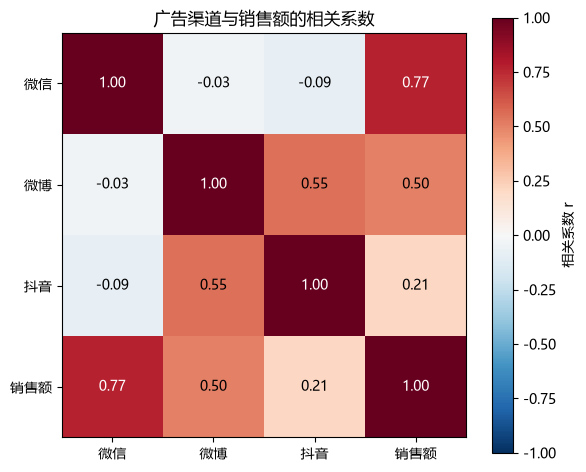

In [5]:
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)

ax.set_xticks(range(len(corr.columns)), corr.columns)
ax.set_yticks(range(len(corr.index)), corr.index)
ax.set_title("广告渠道与销售额的相关系数")

for i in range(len(corr)):
    for j in range(len(corr)):
        value = corr.iloc[i, j]
        color = "white" if abs(value) > 0.55 else "black"
        ax.text(j, i, f"{value:.2f}", ha="center", va="center", color=color)

fig.colorbar(im, ax=ax, label="相关系数 r")
plt.tight_layout()
plt.show()

### 相关系数怎么读

- 微信与销售额：`r ≈ 0.768`，最强正相关；
- 微博与销售额：`r ≈ 0.503`，中等正相关；
- 抖音与销售额：`r ≈ 0.211`，弱正相关；
- 微博与抖音之间：`r ≈ 0.550`，说明老板往往同时加大这两个渠道的投入。

最后一点很重要：微博和抖音之间存在**多重共线性**。在多元回归里，这会让两个渠道的系数变得不稳定，不要单独过度解释某一个系数。

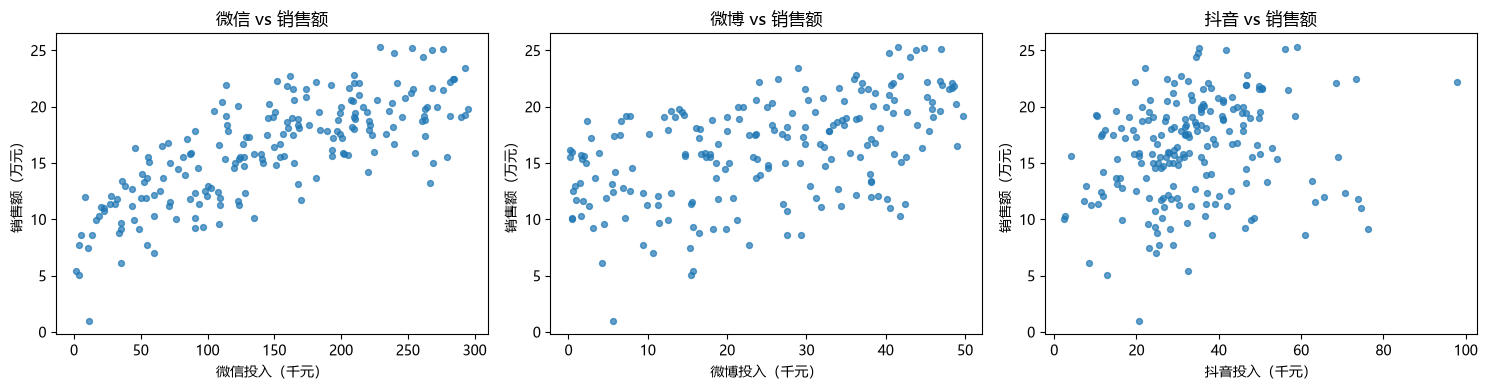

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, ["微信", "微博", "抖音"]):
    ax.scatter(df[col], df["销售额"], s=18, alpha=0.7)
    ax.set_xlabel(f"{col}投入（千元）")
    ax.set_ylabel("销售额（万元）")
    ax.set_title(f"{col} vs 销售额")

plt.tight_layout()
plt.show()

## 3. 假设函数：一条直线

单特征时，最简单的假设是销售额与微信投入呈直线关系：

$$\hat{y}=wx+b$$

- $x$：这一周的微信投入（千元）；
- $\hat{y}$：模型预测的销售额（万元），帽子表示“估计值”；
- $w$：权重（斜率），表示 $x$ 每增加 1，$\hat{y}$ 增加多少；
- $b$：偏置（截距），表示 $x=0$ 时的基准值。

有 $d$ 个特征时，直线推广成超平面：

$$\hat{y}=w_1x_1+w_2x_2+\cdots+w_dx_d+b=\mathbf{w}^{\top}\mathbf{x}+b$$

### sklearn 要求的数据形状

- `X`：二维数组，形状 `(样本数, 特征数)`，即使只有一个特征也不能是一维；
- `y`：一维数组，形状 `(样本数,)`。

`df['微信']` 是 Series（一维）；`df[['微信']]` 是 DataFrame（二维）。

In [7]:
X = df[["微信"]]
y = df["销售额"]

print("X 形状:", X.shape)
print("y 形状:", y.shape)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("训练集:", X_train.shape, "测试集:", X_test.shape)

X 形状: (200, 1)
y 形状: (200,)
训练集: (160, 1) 测试集: (40, 1)


In [8]:
model = LinearRegression().fit(X_train, y_train)

w = model.coef_[0]
b = model.intercept_

print(f"权重 w = {w:.4f}")
print(f"偏置 b = {b:.4f}")
print(f"假设函数: 销售额 = {w:.4f} × 微信投入 + {b:.4f}")

权重 w = 0.0429
偏置 b = 9.6064
假设函数: 销售额 = 0.0429 × 微信投入 + 9.6064


In [9]:
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"MAE  : {mae:.3f} 万元")
print(f"RMSE : {rmse:.3f} 万元")
print(f"R²   : {r2:.3f}")
print(f"训练集 R²: {model.score(X_train, y_train):.3f}")

MAE  : 2.362 万元
RMSE : 2.898 万元
R²   : 0.551
训练集 R²: 0.596


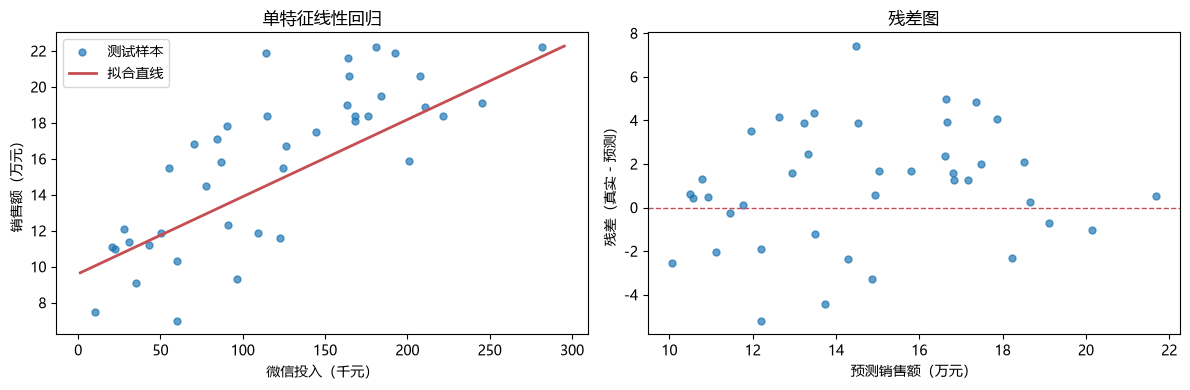

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# 左图：测试样本 + 拟合直线
axes[0].scatter(X_test["微信"], y_test, s=25, alpha=0.7, label="测试样本")
x_line = np.linspace(df["微信"].min(), df["微信"].max(), 100)
y_line = model.predict(pd.DataFrame({"微信": x_line}))
axes[0].plot(x_line, y_line, color="#C44E52", linewidth=2, label="拟合直线")
axes[0].set_xlabel("微信投入（千元）")
axes[0].set_ylabel("销售额（万元）")
axes[0].set_title("单特征线性回归")
axes[0].legend()

# 右图：残差图
residuals = y_test - y_pred
axes[1].scatter(y_pred, residuals, s=25, alpha=0.7)
axes[1].axhline(0, color="#C44E52", linestyle="--", linewidth=1)
axes[1].set_xlabel("预测销售额（万元）")
axes[1].set_ylabel("残差（真实 - 预测）")
axes[1].set_title("残差图")

plt.tight_layout()
plt.show()

### 单特征模型怎么读

- $w$ 的单位是“万元 / 千元”：微信每多投 1 千元，销售额平均增加 $w$ 万元；
- $b$ 是截距，表示微信投入为 0 时的基准销售额；
- $R^2$ 表示模型解释了测试集销售额波动的比例，越接近 1 越好；
- 残差图应围绕 0 随机分布；如果出现明显曲线或喇叭形，说明线性假设可能不够。

## 4. 多特征线性回归

把三个渠道一起放进模型：

$$\hat{y}=w_1x_{\text{微信}}+w_2x_{\text{微博}}+w_3x_{\text{抖音}}+b$$

每个系数表示**控制其他渠道不变**时，该渠道每多投 1 千元，销售额平均变化多少万元。

In [11]:
X_multi = df[["微信", "微博", "抖音"]]
y = df["销售额"]

X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(
    X_multi, y, test_size=0.2, random_state=42
)

model_multi = LinearRegression().fit(X_train_m, y_train_m)

coef_table = pd.DataFrame({
    "特征": X_multi.columns,
    "系数（万元/千元）": model_multi.coef_,
})
coef_table

,特征,系数（万元/千元）
0,微信,0.043242
1,微博,0.167022
2,抖音,-0.006217


In [12]:
for name, coef in zip(X_multi.columns, model_multi.coef_):
    print(f"{name}: 每多投 1 千元，销售额约变化 {coef * 10000:.0f} 元（控制其他渠道不变）")
print(f"截距 b = {model_multi.intercept_:.4f} 万元")

微信: 每多投 1 千元，销售额约变化 432 元（控制其他渠道不变）
微博: 每多投 1 千元，销售额约变化 1670 元（控制其他渠道不变）
抖音: 每多投 1 千元，销售额约变化 -62 元（控制其他渠道不变）
截距 b = 5.7487 万元


In [13]:
y_pred_m = model_multi.predict(X_test_m)

print(f"MAE  : {mean_absolute_error(y_test_m, y_pred_m):.3f} 万元")
print(f"RMSE : {np.sqrt(mean_squared_error(y_test_m, y_pred_m)):.3f} 万元")
print(f"测试集 R²: {r2_score(y_test_m, y_pred_m):.3f}")
print(f"训练集 R²: {model_multi.score(X_train_m, y_train_m):.3f}")

MAE  : 1.403 万元


RMSE : 1.643 万元
测试集 R²: 0.856
训练集 R²: 0.873


In [14]:
comparison = pd.DataFrame({
    "模型": ["微信单特征", "三渠道多特征"],
    "测试集 MAE": [
        mean_absolute_error(y_test, y_pred),
        mean_absolute_error(y_test_m, y_pred_m),
    ],
    "测试集 RMSE": [
        np.sqrt(mean_squared_error(y_test, y_pred)),
        np.sqrt(mean_squared_error(y_test_m, y_pred_m)),
    ],
    "测试集 R²": [
        r2_score(y_test, y_pred),
        r2_score(y_test_m, y_pred_m),
    ],
})
comparison.round(3)

,模型,测试集 MAE,测试集 RMSE,测试集 R²
0,微信单特征,2.362,2.898,0.551
1,三渠道多特征,1.403,1.643,0.856


In [15]:
# 下周计划：微信 200 千元、微博 30 千元、抖音 40 千元
new_week = pd.DataFrame({"微信": [200], "微博": [30], "抖音": [40]})
predicted_sales = model_multi.predict(new_week)[0]
print(f"预测销售额: {predicted_sales:.2f} 万元")

预测销售额: 19.16 万元


## 5. 结果解读与注意点

### 结果

- 单特征（微信）测试集 $R^2 \approx 0.551$；
- 三渠道多特征测试集 $R^2 \approx 0.856$，加入微博、抖音后明显提升；
- 多特征模型里，微博的系数比微信大，但微信与销售额的**相关系数**更高。这两件事不矛盾：相关系数看的是单独变化，回归系数看的是**控制其他渠道后**的边际贡献；
- 抖音系数接近 0（甚至略为负），说明在微信、微博已经进入模型后，抖音的额外信息很少；
- 微博与抖音相关性 0.55，存在多重共线性，系数解释要谨慎。

### 注意

1. **相关不等于因果**：模型能预测，不代表“多投微博就一定多卖”。
2. **线性假设**：残差图若有明显结构，可能需要对数变换、多项式或交互项。
3. **训练集 / 测试集**：测试集只用于最终评估，不能拿来调参。
4. **异常值**：线性回归对异常值敏感，建模前应先检查散点图。
5. **多重共线性**：相关系数高的特征不要同时过度解释；可用 VIF、正则化（Ridge/Lasso）处理。

### 练习

1. 只把微博或只把抖音作为单特征，比较 $R^2$。
2. 对销售额做对数变换，观察 $R^2$ 和残差图是否改善。
3. 加入交互项（如微信 × 微博），看模型是否更好。
4. 用 `cross_val_score` 做 5 折交叉验证，比较单特征与多特征的稳定性。
5. 用 `StandardScaler` 标准化特征后再回归，观察系数变化（预测值不变）。